# 01 — Corrected data sources and isolation

Active model inputs are `results/arsenal_isolated/{league,arsenal}/`. The frozen original bundle is source evidence, not the league model input. These cells audit existing data without training. All dates retain the original chronological partitions.

In [1]:
from pathlib import Path
import sys, json, os
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'experiments/isolated_arsenal.py').exists())
sys.path.insert(0,str(ROOT))
os.environ.setdefault('MPLCONFIGDIR',str(ROOT/'work/matplotlib'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, joblib
from IPython.display import display, Markdown, Image
from experiments import train
from experiments.isolated_arsenal import OUTPUT
RUN=OUTPUT
REVIEW=ROOT/'results/arsenal_isolated_review'
(REVIEW/'figures').mkdir(parents=True,exist_ok=True)
record=json.loads((RUN/'manifest.json').read_text())
for rel,digest in record['artifact_sha256'].items():
    assert train.digest(RUN/rel)==digest,rel
features=record['features']
plt.rcParams.update({'figure.figsize':(11,5),'axes.spines.top':False,'axes.spines.right':False})
def finish(name):
    plt.tight_layout(); plt.savefig(REVIEW/'figures'/f'{name}.png',dpi=110,bbox_inches='tight'); plt.show(); plt.close()
def load(population,split):
    folder=RUN/population/split
    return (pd.read_csv(folder/'X.csv').astype(np.float32),pd.read_csv(folder/'y.csv').target_result.map({'A':0,'D':1,'H':2}).to_numpy(),pd.read_csv(folder/'index.csv'))
def predict(name,x):
    if name.endswith('mlp'):
        return train.predict_checkpoint(RUN/'models'/f'{name}_best.pt',x).to_numpy()
    return joblib.load(RUN/'models'/f'{name}.joblib').predict_proba(x)
metrics=pd.read_csv(RUN/'evaluation/metrics.csv')
names=metrics.model.drop_duplicates().tolist()
# Source duplicate is a deterministic replication, excluded from model selection.
candidates=[n for n in names if n!='league_frozen_source_mlp']
validation=metrics.query("split=='validation'").set_index('model').loc[candidates]
selected=validation.log_loss.idxmin()


Fontconfig error: No writable cache directories


## Raw sources and overlap
Supplementary sources cross-check shared fixtures; they add no training rows. Raw archive plots below describe input evidence before Arsenal exclusion.

,source,rows,columns_after_normalization,first_date,last_date,unique_fixtures,overlap_with_primary,additional_fixtures
0,reza,9880,21,2000-08-19,2026-05-24,9880,9880,0
1,tara,3800,19,2010-08-14,2020-07-26,3800,3800,0
2,football_data_1516,380,19,2015-08-08,2016-05-17,380,380,0
3,football_data_2425,380,19,2024-08-16,2025-05-25,380,380,0
4,football_data_2526,380,19,2025-08-15,2026-05-24,380,380,0


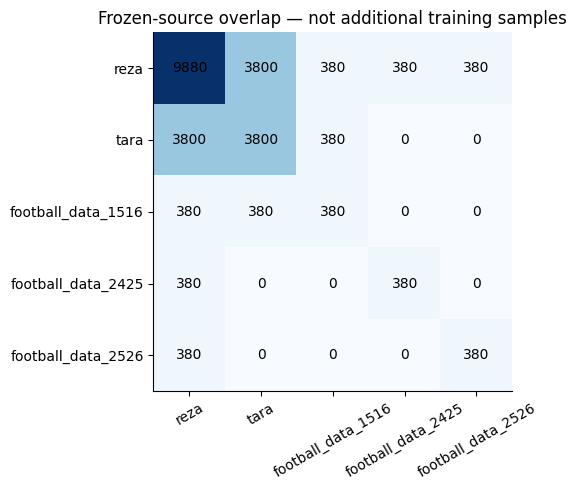

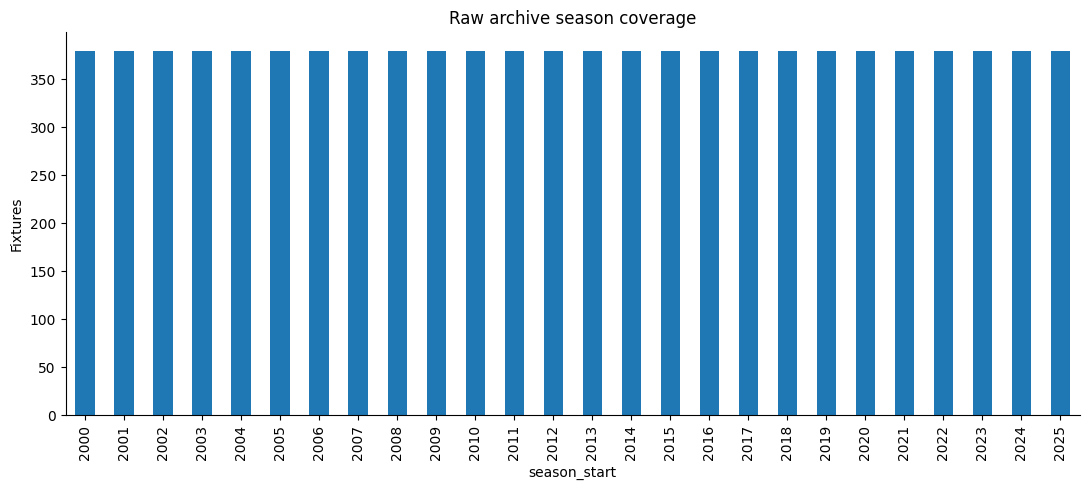

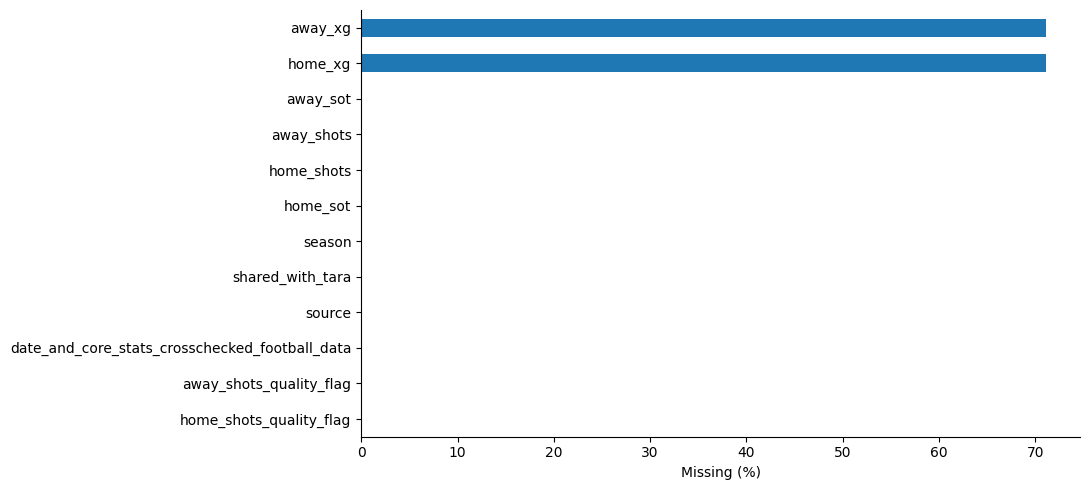

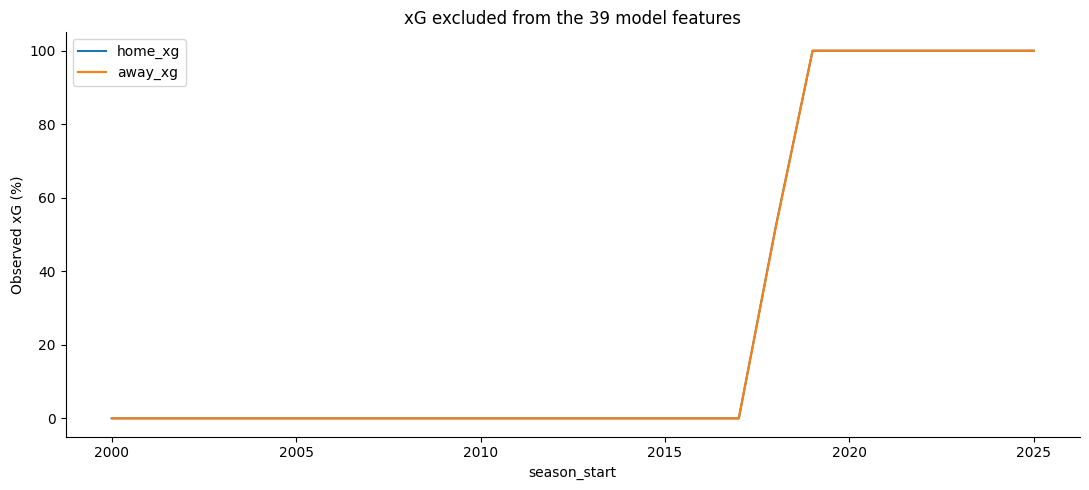

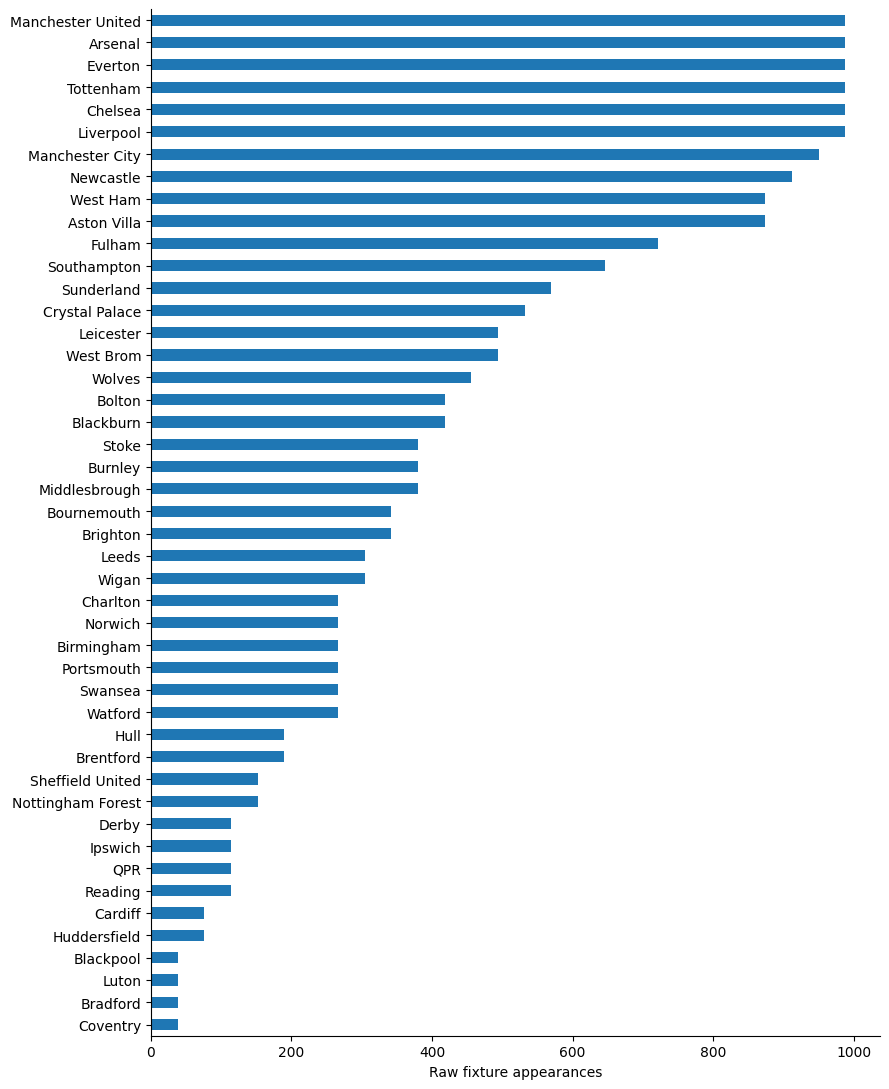

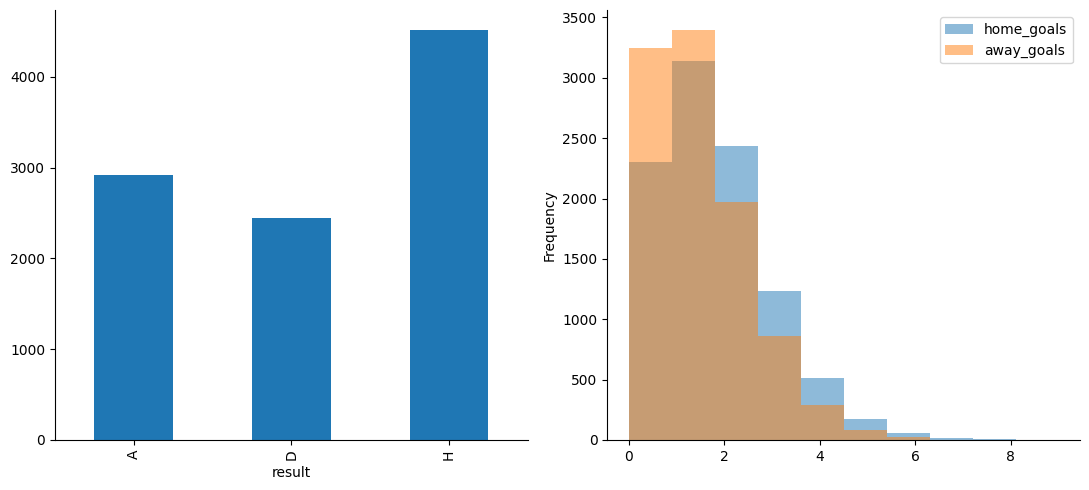

In [2]:
sources=pd.read_csv(ROOT/'results/current/data/source_summary.csv')
display(sources)
overlap=pd.read_csv(ROOT/'results/current/data/source_overlap.csv',index_col=0)
fig,ax=plt.subplots(); im=ax.imshow(overlap.to_numpy(),cmap='Blues');ax.set_xticks(range(len(overlap)),overlap.columns,rotation=30);ax.set_yticks(range(len(overlap)),overlap.index)
for i in range(len(overlap)):
    for j in range(len(overlap)): ax.text(j,i,str(overlap.iloc[i,j]),ha='center',va='center')
ax.set_title('Frozen-source overlap — not additional training samples');finish('01_source_overlap')
raw=pd.read_csv(train.DATA/'data/matches_clean.csv')
raw.groupby('season_start').size().plot.bar();plt.ylabel('Fixtures');plt.title('Raw archive season coverage');finish('02_season_coverage')
raw.isna().mean().sort_values().tail(12).mul(100).plot.barh();plt.xlabel('Missing (%)');finish('03_missingness')
raw.groupby('season_start')[['home_xg','away_xg']].agg(lambda x:x.notna().mean()*100).plot();plt.ylabel('Observed xG (%)');plt.title('xG excluded from the 39 model features');finish('04_xg_coverage')
pd.concat([raw.home_team,raw.away_team]).value_counts().sort_values().plot.barh(figsize=(9,11));plt.xlabel('Raw fixture appearances');finish('05_team_coverage')
fig,axs=plt.subplots(1,2);raw.result.value_counts().reindex(['A','D','H']).plot.bar(ax=axs[0]);raw[['home_goals','away_goals']].plot.hist(bins=10,alpha=.5,ax=axs[1]);finish('06_raw_outcomes')

## Corrected splits and feature reconstruction
Arsenal fixtures are removed before source histories and Elo are computed. League: 7,142/654/656; Arsenal: 815/74/75. Source checkpoints use only non-Arsenal validation. Target features retain actual strictly earlier histories, creating a source/target distribution difference. Earlier observed evaluation-period matches may update pre-match histories, never model weights.

,population,split,n,first,last
0,league,train,7142,2000-09-16,2022-05-22
1,league,validation,654,2022-08-06,2024-05-19
2,league,test,656,2024-08-16,2026-05-24
3,arsenal,train,815,2000-09-16,2022-05-22
4,arsenal,validation,74,2022-08-05,2024-05-19
5,arsenal,test,75,2024-08-17,2026-05-24


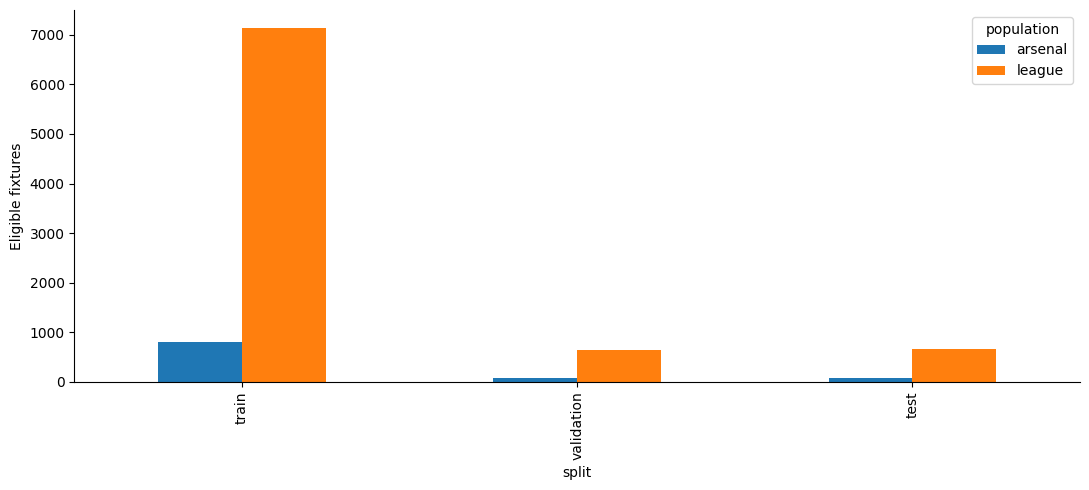

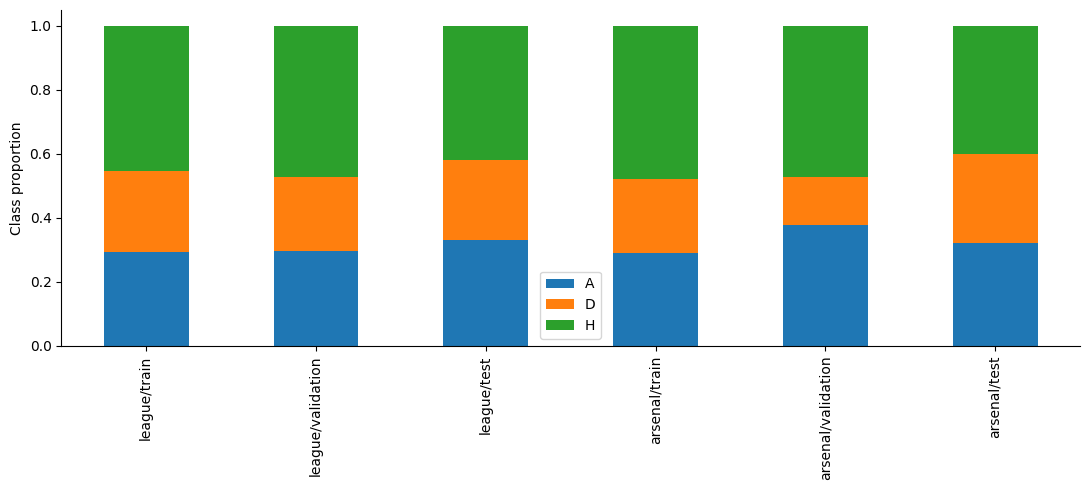

,match_id,date,season_start,home_team,away_team,split,reason
0,0ceaf8d2cb42c57b,2000-08-19,2000,Leeds,Everton,train,Incomplete pre-match features after Arsenal hi...
1,58ed09c518db22cd,2000-08-19,2000,Liverpool,Bradford,train,Incomplete pre-match features after Arsenal hi...
2,aa81d1dcf2aa9fae,2000-08-19,2000,Tottenham,Ipswich,train,Incomplete pre-match features after Arsenal hi...
3,bf10594aa2b23493,2000-08-19,2000,Leicester,Aston Villa,train,Incomplete pre-match features after Arsenal hi...
4,bf1ad191b0bae94a,2000-08-19,2000,Charlton,Manchester City,train,Incomplete pre-match features after Arsenal hi...
5,ca1bf0da76b3e8e8,2000-08-19,2000,Chelsea,West Ham,train,Incomplete pre-match features after Arsenal hi...
6,d3d4ab7d91d527e8,2000-08-19,2000,Coventry,Middlesbrough,train,Incomplete pre-match features after Arsenal hi...
7,d549f4ef1446bd61,2000-08-19,2000,Derby,Southampton,train,Incomplete pre-match features after Arsenal hi...
8,085caa81878099ba,2000-08-20,2000,Manchester United,Newcastle,train,Incomplete pre-match features after Arsenal hi...
9,5c27ce56def2f21b,2000-08-22,2000,Ipswich,Manchester United,train,Incomplete pre-match features after Arsenal hi...


In [3]:
from experiments.isolated_arsenal import league_features
clean=pd.read_csv(train.DATA/'data/matches_clean.csv',parse_dates=['date'])
rebuilt=league_features(clean)
ready=rebuilt[features].notna().all(axis=1)
identities=[]; counts=[]; balances=[]
for pop in ['league','arsenal']:
    for split in ['train','validation','test']:
        x,y,meta=load(pop,split)
        assert train.arsenal(meta).all() if pop=='arsenal' else not train.arsenal(meta).any()
        assert meta.match_id.is_unique and np.isfinite(x).all().all()
        identities.append(set(meta.match_id));counts.append({'population':pop,'split':split,'n':len(y),'first':meta.date.min(),'last':meta.date.max()})
        balances.append(pd.Series(np.bincount(y,minlength=3)/len(y),index=['A','D','H'],name=f'{pop}/{split}'))
        if pop=='league':
            period={'train':rebuilt.season_start<=2021,'validation':rebuilt.season_start.between(2022,2023),'test':rebuilt.season_start>=2024}[split]
            expected=rebuilt.loc[ready & period]
            assert expected.match_id.tolist()==meta.match_id.tolist()
            np.testing.assert_array_equal(expected[features].to_numpy(dtype=np.float32),x.to_numpy())
for i,ids in enumerate(identities): assert all(not ids & previous for previous in identities[:i])
counts=pd.DataFrame(counts);display(counts)
counts.pivot(index='split',columns='population',values='n').reindex(['train','validation','test']).plot.bar();plt.ylabel('Eligible fixtures');finish('07_corrected_splits')
pd.DataFrame(balances).plot.bar(stacked=True);plt.ylabel('Class proportion');finish('08_class_balance')
display(pd.read_csv(RUN/'excluded_league_fixtures.csv').head(10))

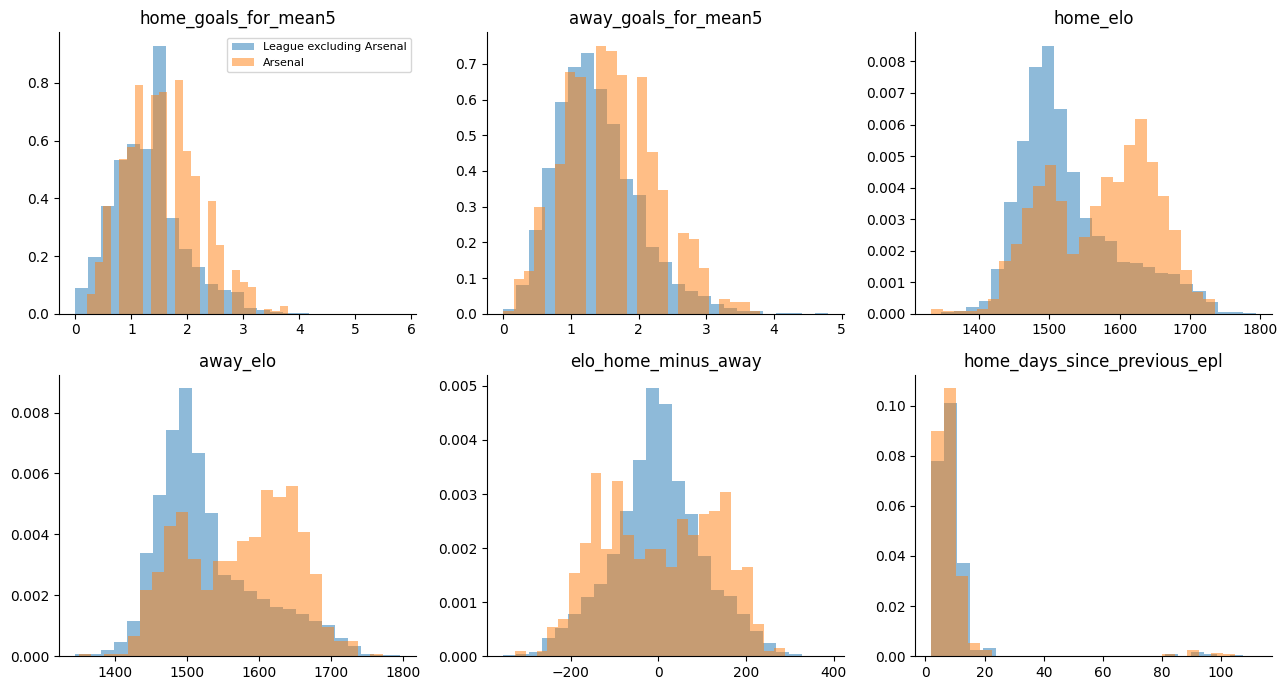

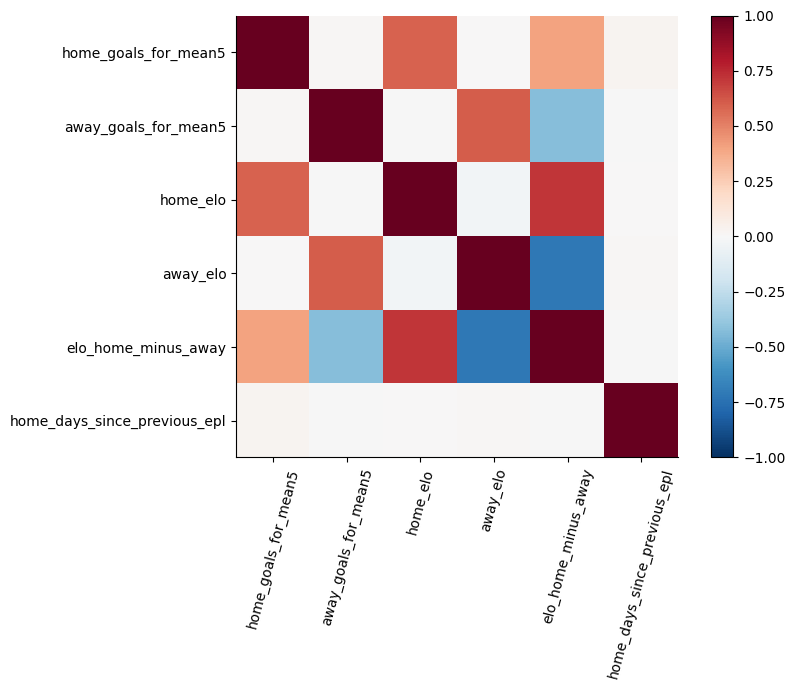

Reconstructed source inputs match every saved eligible feature row.


In [4]:
xl,_,_=load('league','train'); xa,_,_=load('arsenal','train')
chosen=['home_goals_for_mean5','away_goals_for_mean5','home_elo','away_elo','elo_home_minus_away','home_days_since_previous_epl']
fig,axs=plt.subplots(2,3,figsize=(13,7))
for ax,f in zip(axs.flat,chosen):
    ax.hist(xl[f],bins=25,density=True,alpha=.5,label='League excluding Arsenal');ax.hist(xa[f],bins=25,density=True,alpha=.5,label='Arsenal');ax.set_title(f)
axs.flat[0].legend(fontsize=8);finish('09_training_distributions')
fig,ax=plt.subplots(figsize=(9,7));im=ax.imshow(xl[chosen].corr(),vmin=-1,vmax=1,cmap='RdBu_r');ax.set_xticks(range(6),chosen,rotation=75);ax.set_yticks(range(6),chosen);fig.colorbar(im);finish('10_source_training_correlations')
print('Reconstructed source inputs match every saved eligible feature row.')